# Tuckute-Style Audio Model vs Human fMRI Analysis

This notebook supports two datasets from the Tuckute 2023 release:
- `dataset = 'NH2015'` or `dataset = 'N2015'`
- `dataset = 'B2021'`

It loads or computes results for `CLAP`, `MuLAN`, `MERT`, and the Tuckute `spectemp` baseline.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'ismir2026' / 'natural_sound_align').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ismir2026.natural_sound_align.cache_summary import build_metric_summaries, collect_layerwise_metrics, select_model_artifact
from ismir2026.natural_sound_align.pipeline import DEFAULT_OUTPUT_ROOT
from ismir2026.natural_sound_align.rsa import plot_model_vs_human_rdm

dataset = 'NH2015'  # 'NH2015', 'N2015', or 'B2021'
layer_mode = 'final'  # 'final' or 'best'
layerwise_model = 'CLAP'  # 'CLAP', 'MULAN', or 'MERT'
# RSA uses the Tuckute Figure 2E preprocessing: mean_subtract=True, with_std=True

bundle = build_metric_summaries(
    dataset_name=dataset,
    layer_mode=layer_mode,
    output_root=DEFAULT_OUTPUT_ROOT,
    overwrite=False,
)
analysis = bundle.base_analysis
regression_summary = bundle.regression_summary.reset_index(drop=True)
rsa_summary = bundle.rsa_summary.reset_index(drop=True)
layer_tables = bundle.layerwise_tables

foundation_regression = regression_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_regression = regression_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)
foundation_rsa = rsa_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_rsa = rsa_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)

layer_mode_label = 'Best layer' if layer_mode == 'best' else 'Final layer'

display(regression_summary)
display(rsa_summary)


,model_name,representation_name,n_voxels,n_splits,source_dim,median_noise_corrected_r2,mean_noise_corrected_r2,median_noise_corrected_r2_raw,mean_noise_corrected_r2_raw,median_r2,...,median_train_r2,mean_alpha,median_alpha,n_subjects,cv_subject_mean,cv_subject_median,cv_subject_sem,cv_subject_std,value_column,dataset_name
0,CLAP,final,7694,10,768,0.702076,0.670691,0.702076,0.708387,0.304697,...,0.882876,1.727953e+46,100.0,8,0.696856,0.703268,0.017247,0.048781,median_r2_test_c,NH2015
1,MERT,final,7694,10,1024,0.669036,0.652724,0.669036,0.735522,0.284384,...,0.669589,3.617764e+46,10.0,8,0.675467,0.667306,0.018974,0.053665,median_r2_test_c,NH2015
2,MULAN,final,7694,10,512,0.649542,0.615709,0.649542,0.648039,0.286521,...,0.562311,2.610390e+46,1.0,8,0.649093,0.657595,0.012369,0.034986,median_r2_test_c,NH2015
3,SPECTEMP,avgpool,7694,10,23421,0.542200,0.544965,0.542200,0.597126,0.211782,...,0.563120,4.722540e+46,10000.0,8,0.548215,0.554878,0.019209,0.054331,median_r2_test_c,NH2015


,model_name,representation_name,n_repetitions,n_participants,n_splits,mean_spearman,median_spearman,participant_sem,mean_leave_one_out_neural_spearman,dataset_name
0,SPECTEMP,avgpool,8,8,10,0.412462,0.410600,0.011872,0.754764,NH2015
1,CLAP,final,8,8,10,0.377013,0.381570,0.005055,0.754764,NH2015
2,MULAN,final,8,8,10,0.324904,0.322083,0.006686,0.754764,NH2015
3,MERT,final,8,8,10,0.309572,0.300608,0.008458,0.754764,NH2015


## Figure 2A Style Regression Summary

Bars show the foundation models using the Tuckute-style subject-level summary: median across voxels per subject, then mean across subjects after `CV-splits-nit-10` aggregation. The dashed line marks the `spectemp` baseline on that same metric.

,dataset_name,model_name,representation_name,cv_subject_mean,cv_subject_median,median_noise_corrected_r2
0,NH2015,CLAP,final,0.696856,0.703268,0.702076
1,NH2015,MERT,final,0.675467,0.667306,0.669036
2,NH2015,MULAN,final,0.649093,0.657595,0.649542
3,NH2015,SPECTEMP,avgpool,0.548215,0.554878,0.542200


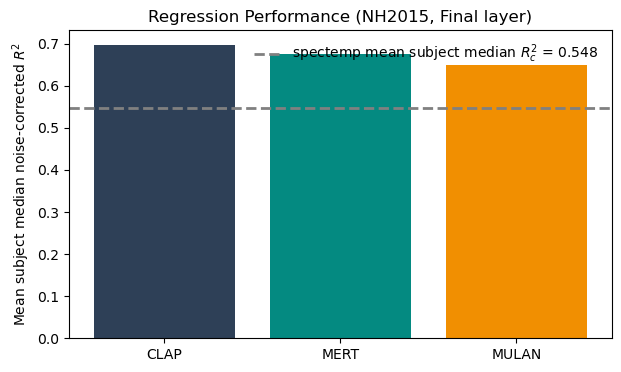

In [2]:
display(regression_summary[['dataset_name', 'model_name', 'representation_name', 'cv_subject_mean', 'cv_subject_median', 'median_noise_corrected_r2']])

baseline_subject_mean = float(spectemp_regression['cv_subject_mean'].iloc[0]) if len(spectemp_regression) else None

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#2E4057', '#048A81', '#F18F01']
ax.bar(foundation_regression['model_name'], foundation_regression['cv_subject_mean'], color=colors[:len(foundation_regression)])
if baseline_subject_mean is not None:
    ax.axhline(baseline_subject_mean, linestyle='--', color='gray', linewidth=2, label=f"spectemp mean subject median $R^2_c$ = {baseline_subject_mean:.3f}")
    ax.legend(frameon=False)
ax.set_ylabel('Mean subject median noise-corrected $R^2$')
ax.set_title(f'Regression Performance ({dataset}, {layer_mode_label})')
plt.show()


,representation_name,layer_depth,cv_subject_mean,median_noise_corrected_r2,is_final
0,layer_00,0,0.015822,0.010231,False
1,layer_01,1,0.571511,0.573594,False
2,layer_02,2,0.712435,0.714342,False
3,layer_03,3,0.750429,0.751750,False
4,layer_04,4,0.701302,0.708497,False
5,final,5,0.696856,0.702076,True


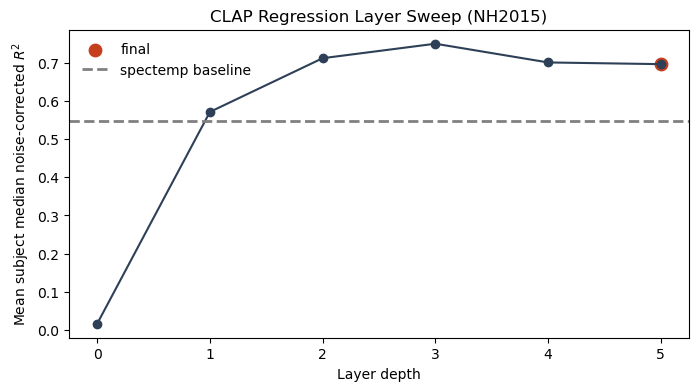

In [3]:
regression_layerwise = layer_tables.get(layerwise_model)
if regression_layerwise is None:
    regression_layerwise = collect_layerwise_metrics(
        layerwise_model,
        dataset_name=dataset,
        output_root=DEFAULT_OUTPUT_ROOT,
        overwrite=False,
    )

display(regression_layerwise[['representation_name', 'layer_depth', 'cv_subject_mean', 'median_noise_corrected_r2', 'is_final']])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(regression_layerwise['layer_depth'], regression_layerwise['cv_subject_mean'], marker='o', color='#2E4057')
final_row = regression_layerwise.query('is_final').iloc[0]
ax.scatter([final_row['layer_depth']], [final_row['cv_subject_mean']], color='#C73E1D', s=80, label='final')
if len(spectemp_regression):
    ax.axhline(float(spectemp_regression['cv_subject_mean'].iloc[0]), linestyle='--', color='gray', linewidth=2, label='spectemp baseline')
ax.set_xlabel('Layer depth')
ax.set_ylabel('Mean subject median noise-corrected $R^2$')
ax.set_title(f'{layerwise_model} Regression Layer Sweep ({dataset})')
ax.legend(frameon=False)
plt.show()


## Figure 2E Style RSA Summary

,dataset_name,model_name,representation_name,mean_spearman,median_spearman,n_participants
0,NH2015,SPECTEMP,avgpool,0.412462,0.410600,8
1,NH2015,CLAP,final,0.377013,0.381570,8
2,NH2015,MULAN,final,0.324904,0.322083,8
3,NH2015,MERT,final,0.309572,0.300608,8


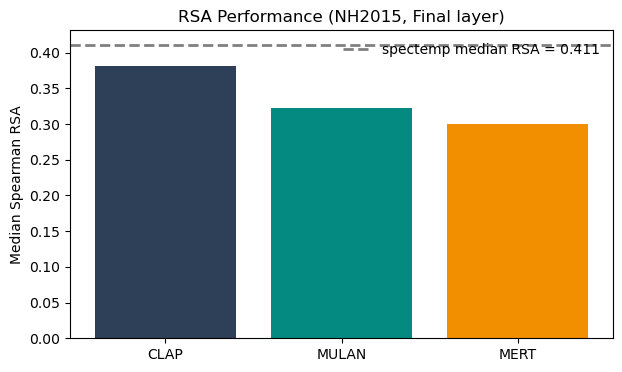

In [4]:
display(rsa_summary[['dataset_name', 'model_name', 'representation_name', 'mean_spearman', 'median_spearman', 'n_participants']])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(foundation_rsa['model_name'], foundation_rsa['median_spearman'], color=['#2E4057', '#048A81', '#F18F01'][:len(foundation_rsa)])
if len(spectemp_rsa):
    baseline_rsa = float(spectemp_rsa['median_spearman'].iloc[0])
    ax.axhline(baseline_rsa, linestyle='--', color='gray', linewidth=2, label=f"spectemp median RSA = {baseline_rsa:.3f}")
    ax.legend(frameon=False)
ax.set_ylabel('Median Spearman RSA')
ax.set_title(f'RSA Performance ({dataset}, {layer_mode_label})')
plt.show()


,representation_name,layer_depth,median_spearman,mean_spearman,is_final
0,layer_00,0,0.057851,0.067755,False
1,layer_01,1,0.401402,0.397860,False
2,layer_02,2,0.420338,0.421643,False
3,layer_03,3,0.410127,0.406921,False
4,layer_04,4,0.376606,0.372732,False
5,final,5,0.381570,0.377013,True


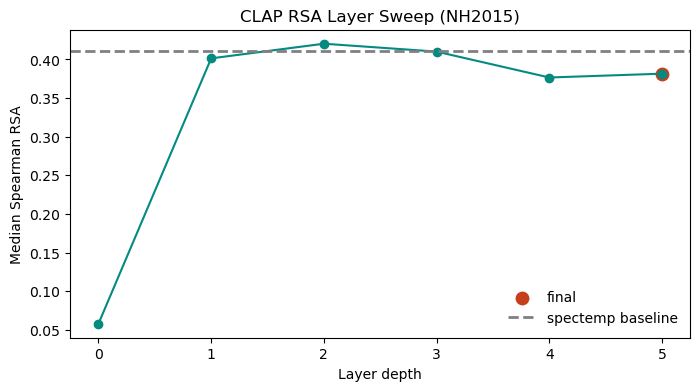

In [5]:
rsa_layerwise = layer_tables.get(layerwise_model)
if rsa_layerwise is None:
    rsa_layerwise = collect_layerwise_metrics(
        layerwise_model,
        dataset_name=dataset,
        output_root=DEFAULT_OUTPUT_ROOT,
        overwrite=False,
    )

display(rsa_layerwise[['representation_name', 'layer_depth', 'median_spearman', 'mean_spearman', 'is_final']])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rsa_layerwise['layer_depth'], rsa_layerwise['median_spearman'], marker='o', color='#048A81')
final_row = rsa_layerwise.query('is_final').iloc[0]
ax.scatter([final_row['layer_depth']], [final_row['median_spearman']], color='#C73E1D', s=80, label='final')
if len(spectemp_rsa):
    ax.axhline(float(spectemp_rsa['median_spearman'].iloc[0]), linestyle='--', color='gray', linewidth=2, label='spectemp baseline')
ax.set_xlabel('Layer depth')
ax.set_ylabel('Median Spearman RSA')
ax.set_title(f'{layerwise_model} RSA Layer Sweep ({dataset})')
ax.legend(frameon=False)
plt.show()


## Human vs Model RDM

Set `model` to one of `CLAP`, `MULAN`, `MERT`, or `SPECTEMP`.

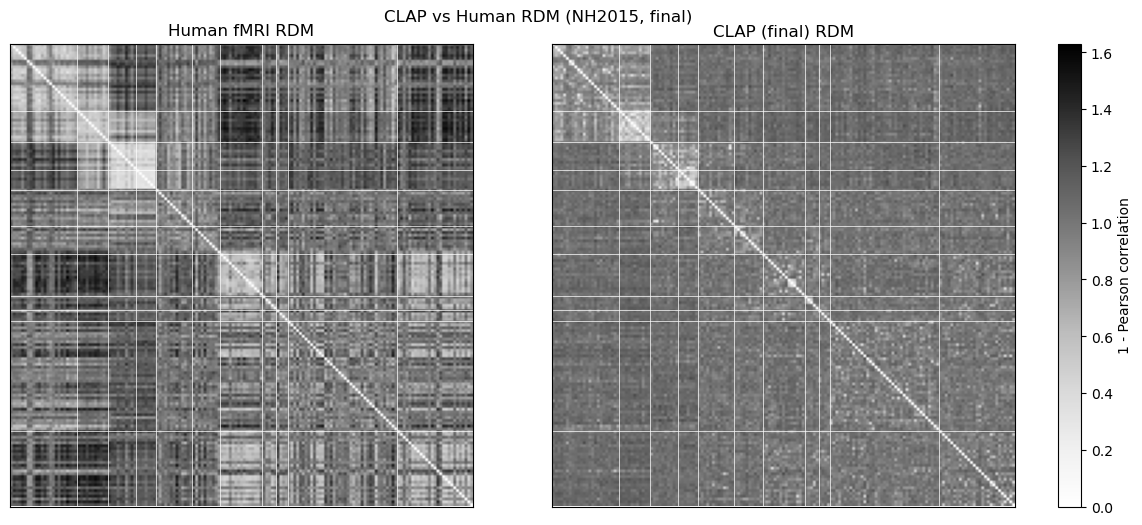

In [6]:
rdm_artifact, selected_layer = select_model_artifact(
    layerwise_model,
    dataset_name=dataset,
    layer_mode=layer_mode,
    target_metric='median_spearman',
    output_root=DEFAULT_OUTPUT_ROOT,
    overwrite=False,
)
selected_label = 'final' if selected_layer is None else str(selected_layer['representation_name'])

fig, axes = plot_model_vs_human_rdm(
    rdm_artifact['rsa'].model_correlation_matrix,
    rdm_artifact['rsa'].mean_human_correlation_matrix,
    rdm_artifact['brain'].metadata,
    model_name=f"{layerwise_model} ({selected_label})",
    reorder_by_category=True,
)
fig.suptitle(f'{layerwise_model} vs Human RDM ({dataset}, {selected_label})', y=1.02)
plt.show()
